# 임베딩 실습: 단어 벡터의 코사인 유사도와 군집

무료 임베딩 모델로 단어 30개를 벡터로 바꾼 뒤, 벡터끼리 얼마나 가까운지를 표와 그림으로 확인합니다.

**실행 전에 할 일**

- Colab 메뉴 「런타임 → 런타임 유형 변경」에서 **T4 GPU** 를 고르면 빠릅니다. GPU 가 없어도 CPU 로 끝까지 실행됩니다.
- 셀은 위에서부터 차례로 실행합니다. 처음 모델을 내려받을 때 1～2분 걸립니다.

## 1. 준비

라이브러리를 설치하고, GPU 를 쓸 수 있는지 확인합니다. `koreanize-matplotlib` 는 그림에 한글이 깨지지 않게 해 주는 패키지입니다.

In [ ]:
!pip -q install sentence-transformers umap-learn koreanize-matplotlib

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib  # 그림의 한글 글꼴
import torch
from sentence_transformers import SentenceTransformer

device = "cuda" if torch.cuda.is_available() else "cpu"
print("사용 장치:", device)

사용 장치: cuda


## 2. 단어 30개의 임베딩

범주 5개에서 단어를 6개씩, 모두 30개 고릅니다. 범주는 정답 확인에만 쓰고, 모델에는 단어만 입력합니다.

In [ ]:
words_by_group = {
    "음식": ["피자", "김밥", "라면", "떡볶이", "비빔밥", "샐러드"],
    "색깔": ["빨강", "파랑", "노랑", "초록", "보라", "검정"],
    "악기": ["피아노", "기타", "바이올린", "드럼", "플루트", "첼로"],
    "감정": ["기쁨", "슬픔", "화남", "두려움", "놀람", "설렘"],
    "학교": ["학생", "선생님", "교실", "칠판", "책상", "운동장"],
}
words = [w for ws in words_by_group.values() for w in ws]
groups = [g for g, ws in words_by_group.items() for _ in ws]
print(len(words), "개:", words)

30 개: ['피자', '김밥', '라면', '떡볶이', '비빔밥', '샐러드', '빨강', '파랑', '노랑', '초록', '보라', '검정', '피아노', '기타', '바이올린', '드럼', '플루트', '첼로', '기쁨', '슬픔', '화남', '두려움', '놀람', '설렘', '학생', '선생님', '교실', '칠판', '책상', '운동장']


KURE-v1 을 불러와 단어 30개를 벡터로 바꿉니다.

`normalize_embeddings=True` 는 **L2 정규화** 옵션입니다. L2 정규화는 벡터의 각 값을 벡터 길이로 나눠 길이를 1 로 만드는 계산입니다. 정규화한 벡터끼리는 내적이 곧 코사인 유사도입니다(「3. 코사인 유사도」).

In [ ]:
model = SentenceTransformer("nlpai-lab/KURE-v1", device=device)
emb = model.encode(words, normalize_embeddings=True)

print("벡터 모양:", emb.shape)          # (단어 수, 차원)
print("「피자」 앞 8개 값:", emb[0][:8].round(3))
print("「피자」 벡터 길이:", np.linalg.norm(emb[0]).round(3))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/220 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/17.3k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/54.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/807 [00:00<?, ?B/s]

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/297 [00:00<?, ?B/s]

벡터 모양: (30, 1024)
「피자」 앞 8개 값: [-0.046  0.026 -0.023  0.034 -0.034  0.039 -0.008  0.042]
「피자」 벡터 길이: 1.0


- `(30, 1024)` 는 단어 30개가 각각 1,024차원 벡터가 되었다는 뜻입니다.
- 수 하나하나가 「과일다움」 같은 정해진 뜻을 갖지는 않습니다. 벡터는 다른 벡터와 비교할 때 쓰입니다.
- 벡터 길이가 1.0 인 것은 L2 정규화를 했기 때문입니다.

In [ ]:
vec = model.encode("피자", normalize_embeddings=True)

print("차원:", vec.shape)        # (1024,)
print("앞 10개 값:", vec[:10].round(4))
print("벡터 길이:", np.linalg.norm(vec).round(3))
print("전체 차원:",vec)

차원: (1024,)
앞 10개 값: [-0.0455  0.0262 -0.0226  0.0342 -0.0344  0.039  -0.0081  0.0417 -0.0075
  0.0105]
벡터 길이: 1.0
전체 차원: [-0.04554958  0.02623253 -0.02263571 ...  0.03604892 -0.07033529
  0.04400744]


In [ ]:
sim = emb @ emb.T
sim_df = pd.DataFrame(sim, index=words, columns=words)

pairs = [("피자", "김밥"), ("빨강", "파랑"), ("피아노", "기쁨"),
          ("기쁨", "설렘"), ("피자", "학생"), ("화남", "바이올린")]
pd.DataFrame([(a, b, round(sim_df.loc[a, b], 3)) for a, b in pairs],
columns=["단어 1", "단어 2", "코사인"])

,단어 1,단어 2,코사인
0,피자,김밥,0.558
1,빨강,파랑,0.617
2,피아노,기쁨,0.469
3,기쁨,설렘,0.643
4,피자,학생,0.500
5,화남,바이올린,0.335


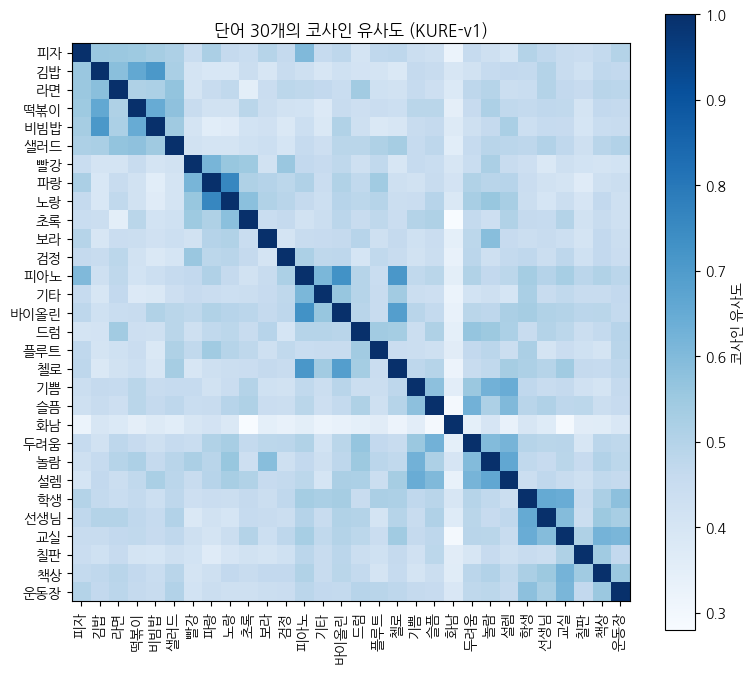

In [ ]:
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(sim, cmap="Blues")
ax.set_xticks(range(len(words)), words, rotation=90)
ax.set_yticks(range(len(words)), words)
fig.colorbar(im, ax=ax, label="코사인 유사도")
ax.set_title("단어 30개의 코사인 유사도 (KURE-v1)")
plt.show()

In [ ]:
same = [sim[i, j] for i in range(30) for j in range(30) if i !=j and groups[i] == groups[j]]
diff = [sim[i, j] for i in range(30) for j in range(30) if groups[i] != groups[j]]
print(f"같은 범주 쌍의 평균 코사인: {np.mean(same):.3f}")
print(f"다른 범주 쌍의 평균 코사인: {np.mean(diff):.3f}")

같은 범주 쌍의 평균 코사인: 0.541
다른 범주 쌍의 평균 코사인: 0.451


In [ ]:
from sklearn.neighbors import NearestNeighbors

nn = NearestNeighbors(n_neighbors=4, metric="cosine").fit(emb)
dist, idx = nn.kneighbors(emb)

rows = []
for i, w in enumerate(words):
    neighbors = [f"{words[j]}({1 - d:.2f})" for d, j in zip(dist[i][1:], idx[i][1:])]
    rows.append([w, groups[i]] + neighbors)
pd.DataFrame(rows, columns=["단어", "범주", "이웃 1", "이웃 2", "이웃 3"])

,단어,범주,이웃 1,이웃 2,이웃 3
0,피자,음식,피아노(0.60),김밥(0.56),라면(0.55)
1,김밥,음식,비빔밥(0.71),떡볶이(0.66),라면(0.58)
2,라면,음식,김밥(0.58),샐러드(0.57),피자(0.55)
3,떡볶이,음식,김밥(0.66),비빔밥(0.65),샐러드(0.57)
4,비빔밥,음식,김밥(0.71),떡볶이(0.65),샐러드(0.54)
5,샐러드,음식,떡볶이(0.57),라면(0.57),비빔밥(0.54)
6,빨강,색깔,파랑(0.62),노랑(0.56),검정(0.56)
7,파랑,색깔,노랑(0.76),빨강(0.62),플루트(0.54)
8,노랑,색깔,파랑(0.76),초록(0.58),놀람(0.56)
9,초록,색깔,노랑(0.58),빨강(0.55),슬픔(0.51)


In [ ]:
nn_euc = NearestNeighbors(n_neighbors=4, metric="euclidean").fit(emb)
_, idx_euc = nn_euc.kneighbors(emb)
print("이웃 순서가 모두 같은가:", (idx == idx_euc).all())

이웃 순서가 모두 같은가: True


In [ ]:
for w in ["피자", "피아노", "기쁨", "선생님", "바이올린"]:
    print(w, "→", model.tokenizer.tokenize(w))

피자 → ['▁피', '자']
피아노 → ['▁', '피아', '노']
기쁨 → ['▁기', '쁨']
선생님 → ['▁선생님']
바이올린 → ['▁', '바이', '올', '린']


In [ ]:
new_words = ["파랑", "운동장", "칠판", "플루트"]
new_emb = model.encode(new_words, normalize_embeddings=True)
dist, idx = nn.kneighbors(new_emb, n_neighbors=3)

for w, d, i in zip(new_words, dist, idx):
    print(w, "→", [f"{words[j]}({1 - x:.2f})" for x, j in zip(d, i)])

파랑 → ['파랑(1.00)', '노랑(0.76)', '빨강(0.62)']
운동장 → ['운동장(1.00)', '교실(0.61)', '학생(0.58)']
칠판 → ['칠판(1.00)', '책상(0.54)', '교실(0.51)']
플루트 → ['플루트(1.00)', '파랑(0.54)', '드럼(0.54)']


In [ ]:
from sklearn.decomposition import PCA
import umap

xy_pca = PCA(n_components=2, random_state=0).fit_transform(emb)
xy_umap = umap.UMAP(n_neighbors=10, min_dist=1.0, spread=5.0, metric="cosine",
                    random_state=0).fit_transform(emb)

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1401: RuntimeWarning: divide by zero encountered in power
  return 1.0 / (1.0 + a * x ** (2 * b))
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


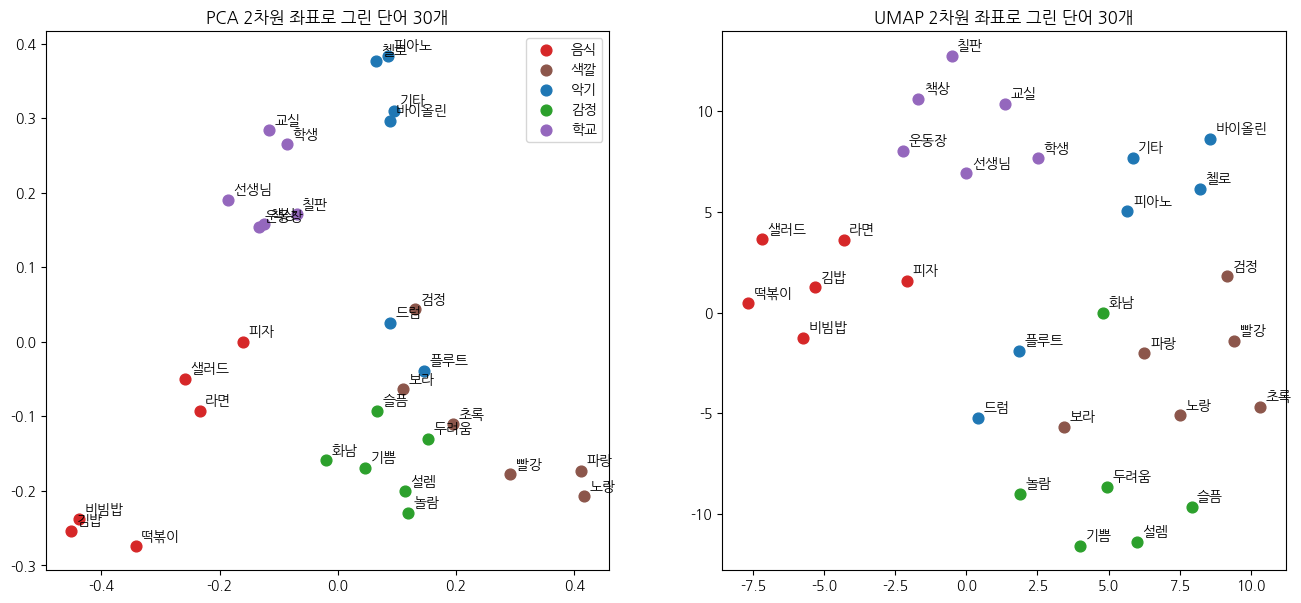

In [ ]:
colors = dict(zip(words_by_group, ["tab:red", "tab:brown", "tab:blue", "tab:green", "tab:purple"]))

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, xy, title in zip(axes, [xy_pca, xy_umap], ["PCA", "UMAP"]):
    for g in words_by_group:
        m = [k for k in range(30) if groups[k] == g]
        ax.scatter(xy[m, 0], xy[m, 1], c=colors[g], label=g, s=60)
    for k, w in enumerate(words):
        ax.annotate(w, xy[k], fontsize=10, xytext=(4, 4), textcoords="offset points")
    ax.set_title(f"{title} 2차원 좌표로 그린 단어 30개")
axes[0].legend()
plt.show()

In [ ]:
from sklearn.cluster import KMeans, AgglomerativeClustering, HDBSCAN
from sklearn.metrics import adjusted_rand_score

methods = {
    "K-평균": KMeans(n_clusters=5, random_state=0),
    "계층적 군집": AgglomerativeClustering(n_clusters=5, metric="cosine", linkage="average"),
    "HDBSCAN": HDBSCAN(min_cluster_size=3),
}
labels = {name: m.fit_predict(emb) for name, m in methods.items()}

pd.DataFrame([
    [name, len(set(lab) - {-1}), int((lab == -1).sum()), round(adjusted_rand_score(groups, lab), 3)]
    for name, lab in labels.items()
], columns=["방법", "군집 수", "이상치 수", "ARI"])

,방법,군집 수,이상치 수,ARI
0,K-평균,5,0,0.295
1,계층적 군집,5,0,0.576
2,HDBSCAN,4,4,0.421


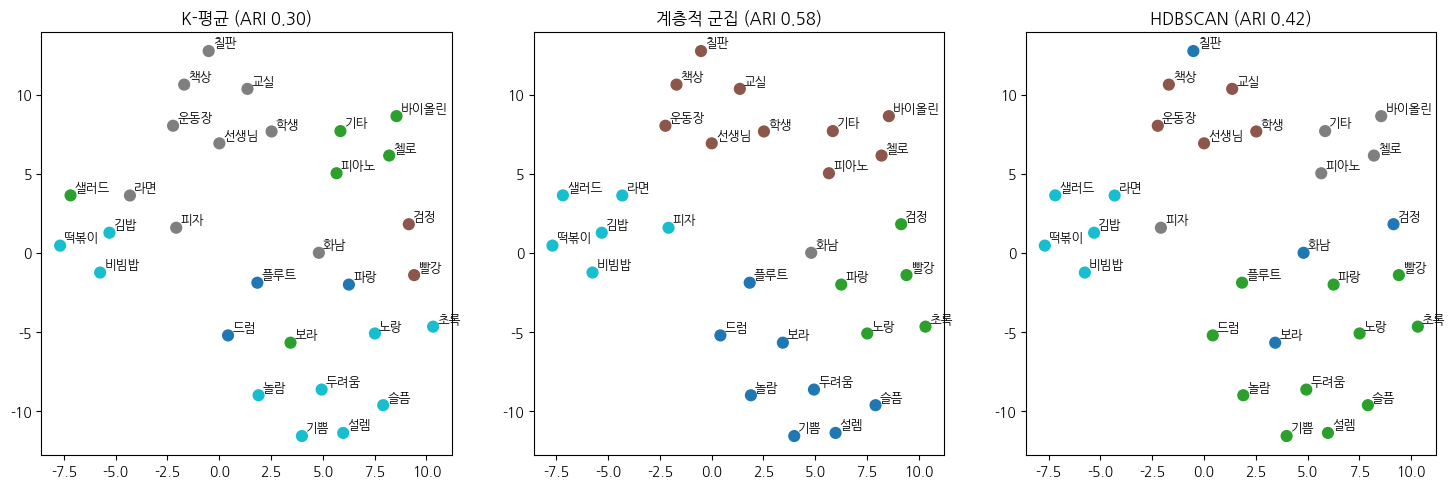

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, (name, lab) in zip(axes, labels.items()):
    ax.scatter(xy_umap[:, 0], xy_umap[:, 1], c=lab, cmap="tab10", s=60)
    for k, w in enumerate(words):
        ax.annotate(w, xy_umap[k], fontsize=9, xytext=(3, 3), textcoords="offset points")
    ax.set_title(f"{name} (ARI {adjusted_rand_score(groups, lab):.2f})")
plt.show()

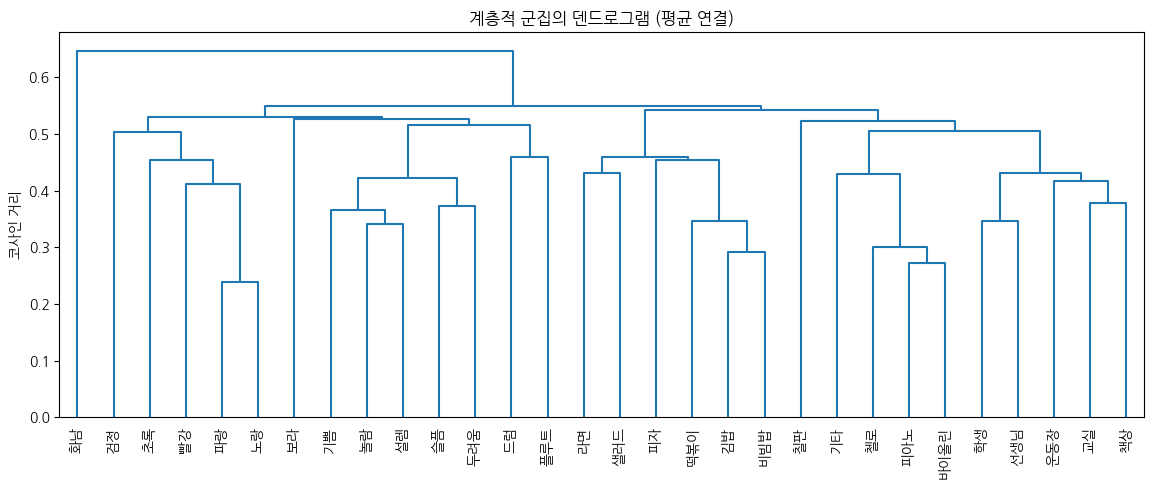

In [ ]:
from scipy.cluster.hierarchy import linkage, dendrogram

Z = linkage(emb, method="average", metric="cosine")
plt.figure(figsize=(14, 5))
dendrogram(Z, labels=words, leaf_rotation=90, color_threshold=0, above_threshold_color="tab:blue")
plt.ylabel("코사인 거리")
plt.title("계층적 군집의 덴드로그램 (평균 연결)")
plt.show()

In [ ]:
candidates = {
    "nlpai-lab/KURE-v1": "",
    "intfloat/multilingual-e5-small": "query: ",
    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2": "",
}

rows = []
for name, prefix in candidates.items():
    m = SentenceTransformer(name, device=device)
    e = m.encode([prefix + w for w in words], normalize_embeddings=True)
    s = e @ e.T
    same = np.mean([s[i, j] for i in range(30) for j in range(30) if i != j and groups[i] == groups[j]])
    diff = np.mean([s[i, j] for i in range(30) for j in range(30) if groups[i] != groups[j]])
    ari = adjusted_rand_score(groups, KMeans(n_clusters=5, n_init=10, random_state=0).fit_predict(e))
    rows.append([name.split("/")[-1], e.shape[1], round(same, 3), round(diff, 3), round(ari, 3)])

pd.DataFrame(rows, columns=["모델", "차원", "같은 범주 평균 코사인", "다른 범주 평균 코사인", "K-평균 ARI"])

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/498k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 9.08MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

,모델,차원,같은 범주 평균 코사인,다른 범주 평균 코사인,K-평균 ARI
0,KURE-v1,1024,0.541,0.451,0.675
1,multilingual-e5-small,384,0.825,0.806,0.173
2,paraphrase-multilingual-MiniLM-L12-v2,384,0.596,0.520,0.109
